# LAB 1 - Bài 2 (Trang 30): Xử lý dữ liệu cảm biến tb_tracking.xlsx

### a. Thêm vào tiêu đề các cột

In [2]:
HO_TEN = "Nguyễn Đoàn Ngọc Hiệp"
MSSV = "6451071023"

def info():
    print(f"Họ và tên: {HO_TEN} - MSSV: {MSSV}")
    print("-" * 30)

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# File không có dòng tiêu đề nên đọc với header=None rồi tự đặt tên cột
df = pd.read_excel('tb_tracking.xlsx', header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']

info()
print("--- Kết quả Câu a (5 dòng đầu sau khi đặt tên cột) ---")
display(df.head())
print("Kích thước dữ liệu:", df.shape)

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
--- Kết quả Câu a (5 dòng đầu sau khi đặt tên cột) ---


,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01


Kích thước dữ liệu: (33340, 6)


### b. Lọc dữ liệu từ ngày 03/01/2018

In [3]:
info()
df['time'] = pd.to_datetime(df['time'])

print(f"Số dòng trước khi lọc: {len(df)}")
df = df[df['time'] >= pd.Timestamp('2018-01-03')]   # 03/01/2018 = ngày 3 tháng 1 năm 2018
print(f"Số dòng sau khi lọc từ ngày 03/01/2018: {len(df)}")

print("--- Kết quả Câu b (5 dòng đầu sau khi lọc) ---")
display(df.head())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
Số dòng trước khi lọc: 33340
Số dòng sau khi lọc từ ngày 03/01/2018: 1918
--- Kết quả Câu b (5 dòng đầu sau khi lọc) ---


,id,device_id,co_level,humidity,temperature,time
31419,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07
31420,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10
31421,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30
31422,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21
31423,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17


### c. Tạo cột minutes từ cột time
`minutes` = số phút tính từ 00:00 của ngày đó = giờ × 60 + phút.

In [4]:
info()
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

print("--- Kết quả Câu c (các cột kèm cột minutes mới) ---")
display(df[['id', 'time', 'minutes']].head())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
--- Kết quả Câu c (các cột kèm cột minutes mới) ---


,id,time,minutes
31419,31420.0,2018-01-03 13:11:07,791
31420,31421.0,2018-01-03 13:15:10,795
31421,31422.0,2018-01-03 13:17:30,797
31422,31423.0,2018-01-03 13:19:21,799
31423,31424.0,2018-01-03 13:24:17,804


### d. Vẽ đồ thị phân tán
Ba đồ thị cùng trục hoành `minutes`: nồng độ CO, độ ẩm và nhiệt độ.

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


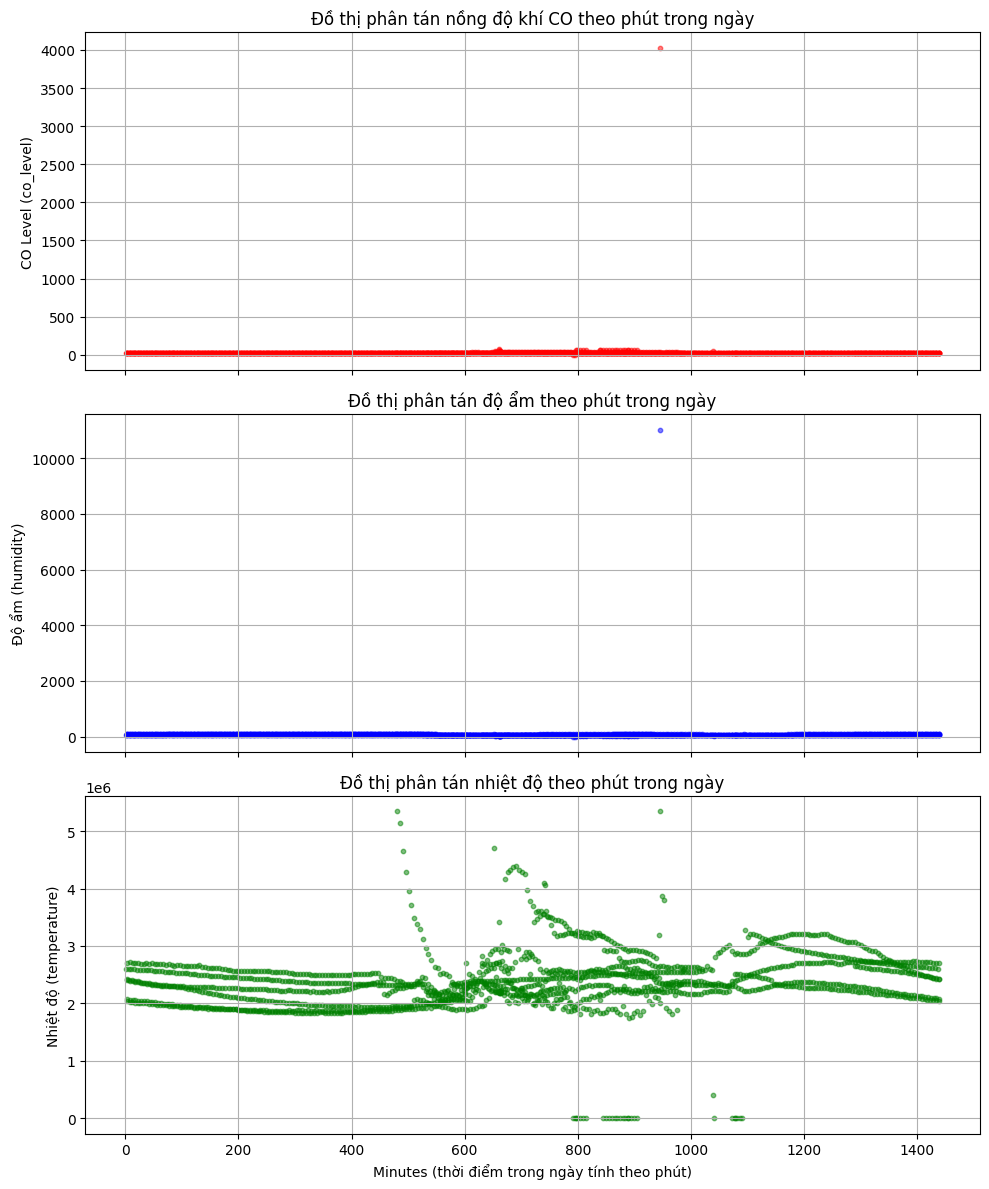

In [5]:
info()
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 12), sharex=True)

axes[0].scatter(df['minutes'], df['co_level'], color='r', alpha=0.5, s=10)
axes[0].set_ylabel('CO Level (co_level)')
axes[0].set_title('Đồ thị phân tán nồng độ khí CO theo phút trong ngày')
axes[0].grid(True)

axes[1].scatter(df['minutes'], df['humidity'], color='b', alpha=0.5, s=10)
axes[1].set_ylabel('Độ ẩm (humidity)')
axes[1].set_title('Đồ thị phân tán độ ẩm theo phút trong ngày')
axes[1].grid(True)

axes[2].scatter(df['minutes'], df['temperature'], color='g', alpha=0.5, s=10)
axes[2].set_xlabel('Minutes (thời điểm trong ngày tính theo phút)')
axes[2].set_ylabel('Nhiệt độ (temperature)')
axes[2].set_title('Đồ thị phân tán nhiệt độ theo phút trong ngày')
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Nhận xét:** (viết nhận xét của bạn sau khi xem biểu đồ)